# EDA 06 · Raw variables versus churn

**Part I · Raw tables** · part of the 10-notebook EDA series in `workshops/w1/eda/` (index in `README.md`).

**Question.** Which raw variables already separate churners from non-churners?

**Data.** Raw files converted to parquet in `workshops/data/parquet/`. The target is the labelled March cohort `train_v2` (970,960 users, 9.0 % churn).

**How to read it.** The tables are merged on `msno`; the density plots compare churn and no-churn directly. Part II repeats this on the engineered features.

In [ ]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Paths resolve from the w1 folder, whether the notebook runs from workshops/w1 or workshops/w1/eda.
W1_DIR = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
DATA_DIR = W1_DIR.parent / "data"      # workshops/data: raw .csv.7z archives
PARQUET_DIR = DATA_DIR / "parquet"     # created once by notebook 01 (or by w1_data_preprocessing)

sns.set()
warnings.filterwarnings("ignore")

PCTS = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 98, 99, 99.5, 99.99, 99.999, 100]


def tabla_percentiles(serie):
    return pd.DataFrame(np.percentile(serie, PCTS), index=PCTS, columns=["valor"])

### Setup carried over from the previous notebooks

The cells below recreate the tables this notebook needs (same code as in the notebooks where they were first analysed; outputs omitted).

In [ ]:
train_data = pl.read_parquet(PARQUET_DIR / "train_v2.parquet").to_pandas()

In [ ]:
# members_v3.parquet; member.csv and member_v2.csv were replaced by the competition sponsors
member_data = pl.read_parquet(PARQUET_DIR / "members_v3.parquet").to_pandas()
member_data["registration_init_time"] = pd.to_datetime(
    member_data["registration_init_time"].astype(str), format="%Y%m%d")

In [ ]:
# transactions_v2.parquet; both transaction files are used in preprocessing
transaction_data = pl.read_parquet(PARQUET_DIR / "transactions_v2.parquet").to_pandas()
for col in ("transaction_date", "membership_expire_date"):
    transaction_data[col] = pd.to_datetime(
        transaction_data[col].astype(str), format="%Y%m%d")

### Analysis

## 6. Bivariate

### Features with respect to the target variable

In [75]:
# merging train data and member data
train_member = pd.merge(train_data, member_data, how="left", on="msno")

In [76]:
train_member.head()

,msno,is_churn,city,registered_via,bd,registration_init_time,gender
0,ugx0CjOMzazClkFzU2xasmDZaoIqOUAZPsH1q0teWCg=,1,5.0,3.0,28.0,2013-12-23,male
1,f/NmvEzHfhINFEYZTR05prUdr+E+3+oewvweYz9cCQE=,1,13.0,3.0,20.0,2013-12-23,male
2,zLo9f73nGGT1p21ltZC3ChiRnAVvgibMyazbCxvWPcg=,1,13.0,3.0,18.0,2013-12-27,male
3,8iF/+8HY8lJKFrTc7iR9ZYGCG2Ecrogbc2Vy5YhsfhQ=,1,1.0,7.0,0.0,2014-01-09,NaN
4,K6fja4+jmoZ5xG6BypqX80Uw/XKpMgrEMdG2edFOxnA=,1,13.0,7.0,35.0,2014-01-25,female


### Plot between

1. gender and count with respect to churn
2. registered_via and count with respect to churn

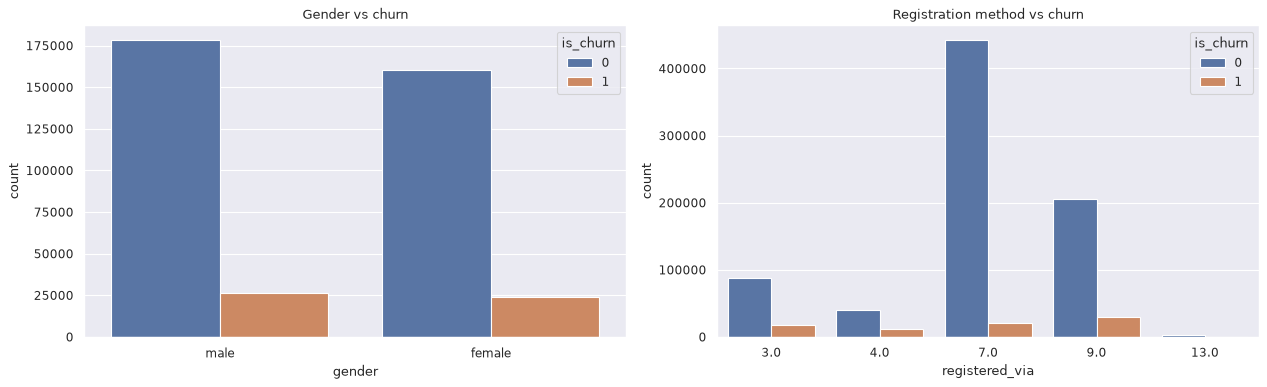

In [77]:
figure(num=None, figsize=(16, 5), dpi=80, facecolor="w", edgecolor="k")
plt.subplot(121)
sns.countplot(data=train_member, x="gender", hue="is_churn")
plt.title("Gender vs churn")
plt.xlabel("gender")
plt.ylabel("count")
plt.subplot(122)
sns.countplot(data=train_member, x="registered_via", hue="is_churn")
plt.title("Registration method vs churn")
plt.xlabel("registered_via")
plt.ylabel("count")
plt.tight_layout()
plt.show()

Gender has very little impact on churning. People who use method 9 have more churn, so we can create a flag for that.

### Plot between city and count with hue as churn

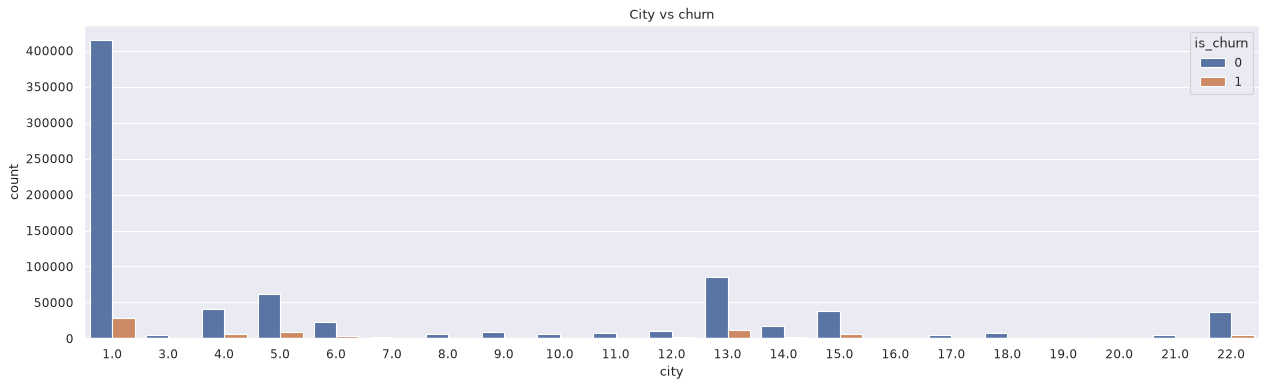

In [78]:
figure(num=None, figsize=(16, 5), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(data=train_member, x="city", hue="is_churn")
plt.title("City vs churn")
plt.xlabel("city")
plt.ylabel("count")
plt.tight_layout()
plt.show()

People in cities 4, 5, 15 and 22 have a higher churn rate. Note that city 13 has a lower churn rate than 5 and 22.

### Plot between density of age with respect to churn

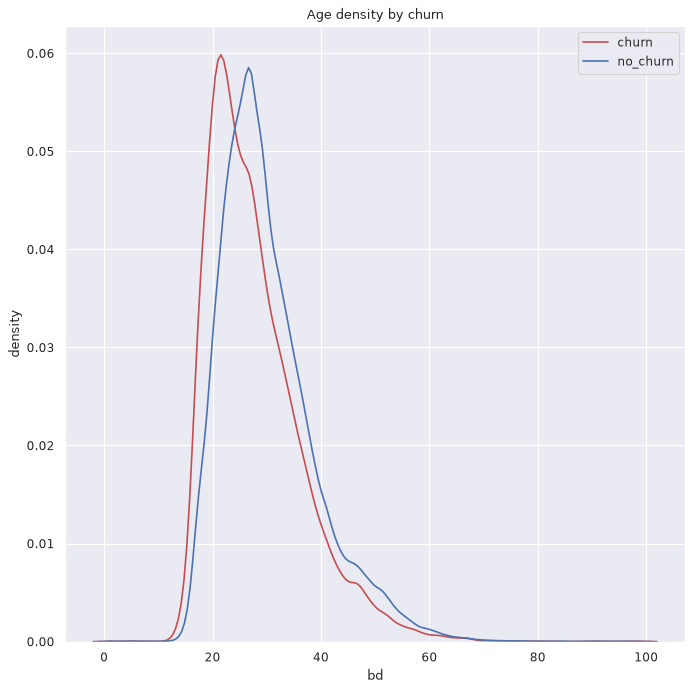

In [79]:
figure(num=None, figsize=(10, 10), dpi=80, facecolor="w", edgecolor="k")
sns.kdeplot(x=train_member["bd"][(train_member["is_churn"] == 1) & (train_member["bd"] > 0) & (train_member["bd"] < 100)], color="r", label="churn")
sns.kdeplot(x=train_member["bd"][(train_member["is_churn"] == 0) & (train_member["bd"] > 0) & (train_member["bd"] < 100)], label="no_churn")
plt.title("Age density by churn")
plt.xlabel("bd")
plt.ylabel("density")
plt.legend()
plt.show()

The plot shows that teenagers tend to churn more. This is not significantly important, but it definitely has some value in differentiating.

In [80]:
# merging all three datasets: train, member and transaction
train_member_transaction = pd.merge(train_member, transaction_data, how="left", on="msno")

In [81]:
train_member_transaction.head()

,msno,is_churn,city,registered_via,bd,registration_init_time,gender,payment_method_id,payment_plan_days,plan_list_price,actual_amount_paid,is_auto_renew,transaction_date,membership_expire_date,is_cancel
0,ugx0CjOMzazClkFzU2xasmDZaoIqOUAZPsH1q0teWCg=,1,5.0,3.0,28.0,2013-12-23,male,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN
1,f/NmvEzHfhINFEYZTR05prUdr+E+3+oewvweYz9cCQE=,1,13.0,3.0,20.0,2013-12-23,male,36.0,30.0,180.0,180.0,0.0,2017-03-11,2017-04-11,0.0
2,zLo9f73nGGT1p21ltZC3ChiRnAVvgibMyazbCxvWPcg=,1,13.0,3.0,18.0,2013-12-27,male,17.0,60.0,0.0,0.0,0.0,2017-03-11,2017-03-14,0.0
3,zLo9f73nGGT1p21ltZC3ChiRnAVvgibMyazbCxvWPcg=,1,13.0,3.0,18.0,2013-12-27,male,15.0,90.0,300.0,300.0,0.0,2017-03-14,2017-06-15,0.0
4,8iF/+8HY8lJKFrTc7iR9ZYGCG2Ecrogbc2Vy5YhsfhQ=,1,1.0,7.0,0.0,2014-01-09,NaN,41.0,30.0,149.0,149.0,1.0,2015-09-08,2017-06-08,0.0


### Plot between density of price (actual) with respect to churn

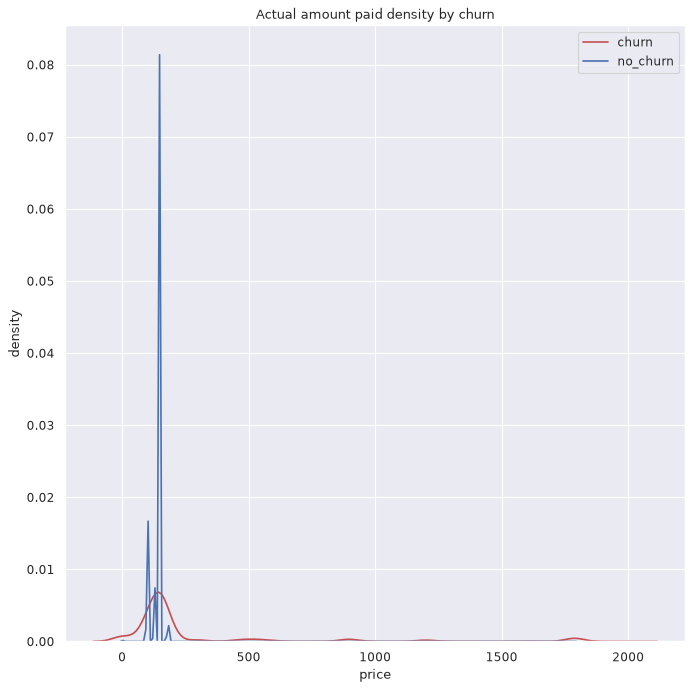

In [82]:
figure(num=None, figsize=(10, 10), dpi=80, facecolor="w", edgecolor="k")
sns.kdeplot(x=train_member_transaction["actual_amount_paid"][train_member_transaction["is_churn"] == 1], color="r", label="churn")
sns.kdeplot(x=train_member_transaction["actual_amount_paid"][train_member_transaction["is_churn"] == 0], label="no_churn")
plt.title("Actual amount paid density by churn")
plt.xlabel("price")
plt.ylabel("density")
plt.legend()
plt.show()

**Bivariate.**

- `gender` barely influences churn. `registered_via = 9` and cities 4, 5, 15 and 22 have more churn. Young users churn slightly more.
- In the pairplot, churn and no-churn overlap, so no raw variable separates the classes well.

In [83]:
# Only for visualization
df_plot = train_member_transaction.drop(columns=["registration_init_time", "transaction_date", "membership_expire_date"]).copy()
df_plot = df_plot.dropna()
df_plot = df_plot.sort_values(by="is_churn", ascending=False).reset_index(drop=True)

### Pair plots

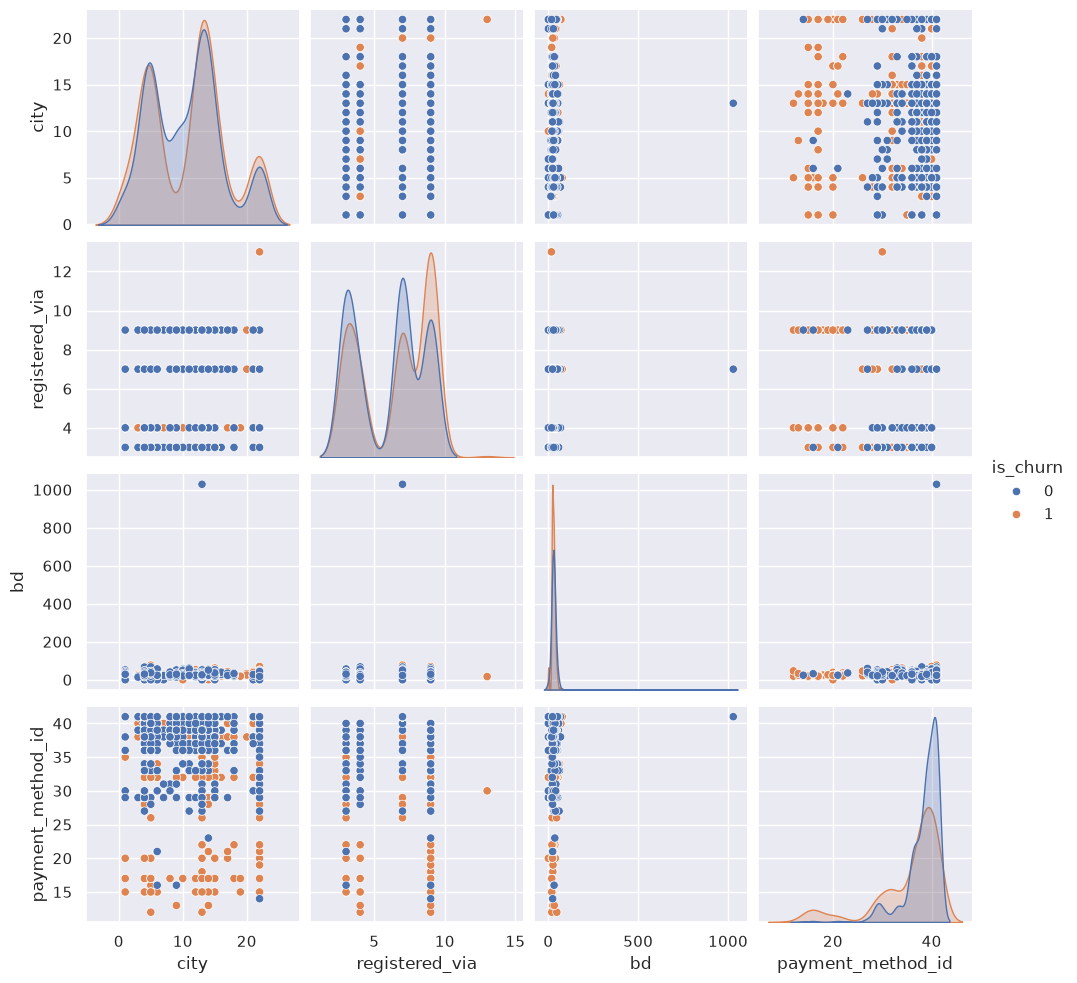

In [84]:
%matplotlib inline
sns.pairplot(data=df_plot[57380:59380].iloc[:, :7], hue="is_churn")

We can see that both churned and not-churned customers almost overlap. It is very difficult to tell which customer will churn with these features; we have to come up with different features that best differentiate both classes. Clearly there are some outliers.

## 7. Conclusions

1. The classes are imbalanced.
2. `bd` and `registered_via` must be cleaned and `gender` discarded.
3. The difference between the list price and the amount paid is a feature.
4. The logs need outlier clipping.
5. Time carries information and must be encoded into features.
6. The signal is spread across variables, so the key is feature engineering and boosting models.

---
**Previous:** `05_dates.ipynb` · **Next:** `07_feature_catalogue_and_target.ipynb`